# Antibiotic-Group Scientific Interest in AMR

This notebook generalizes the yearly AMR scientific-interest workflow from individual antibiotics to a coarser antibiotic abstraction.

The user chooses one grouping column from `antibiotic_list2.xlsx`, for example:

- `Antibiotic`
- `Class`
- `Simplified categories`
- `High level categories`
- or any other column present in the spreadsheet

The workflow then:

1. maps each antibiotic to the chosen group
2. aggregates yearly AMR-positive counts from `(pathogen, antibiotic, year)` to `(pathogen, group, year)`
3. aggregates antibiotic background counts to the same group level
4. runs the same yearly SI modeling on `(pathogen, antibiotic_group, year)` pairs

Internally, the coarser group is renamed to the `antibiotic` column expected by the shared scientific-interest functions.


In [1]:
%config InlineBackend.figure_format = 'retina'

from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import Ridge

from amr.scientific_interest import (
    plot_yearly_si_pair,
    display_si_amr_pareto_front,
    plot_yearly_si_prediction_for_pareto_pairs,
    rank_yearly_pairs_by_future_si_shift,
    select_interesting_yearly_rank_cases,
)


## Configuration

Set `ANTIBIOTIC_GROUP_COLUMN` to any column present in `antibiotic_list2.xlsx`.
The selected grouping column becomes the coarse antibiotic dimension for all downstream analysis.


In [2]:
ANTIBIOTIC_METADATA_PATH = Path("antibiotic_list2.xlsx")
REFINED_SCREEN_PATH = Path("pmids_results_positive_yearly_refined_screen.parquet")
REFINED_PAIR_PMID_PATH = Path("pmids_results_positive_yearly_refined_pair_pmid.parquet")
YEARLY_PATH = Path("pmids_results_positive_yearly_refined.parquet")
PATHOGEN_BG_PATH = Path("pathogen_tiab_counts.parquet")
ANTIBIOTIC_BG_PATH = Path("antibiotic_tiab_counts.parquet")

ANTIBIOTIC_GROUP_COLUMN = "High level categories"
N_ROWS = 10
SHOW_RANDOM_ROWS = True

RANK_FIT_START_YEAR = 1970
RANK_FIT_END_YEAR = 2022
RANK_NUM_FUTURE_YEARS = 20

RANK_OUTPUT_PATH = Path(
    f"si_yearly_rank_shift_{ANTIBIOTIC_GROUP_COLUMN.lower().replace(' ', '_')}_fit_{RANK_FIT_START_YEAR}_{RANK_FIT_END_YEAR}_ref_{RANK_FIT_END_YEAR}_future_{RANK_FIT_END_YEAR + RANK_NUM_FUTURE_YEARS}.parquet"
)
PARETO_PNG_DIR = Path(f"pareto_pngs_yearly_{ANTIBIOTIC_GROUP_COLUMN.lower().replace(' ', '_')}")
INTERESTING_PNG_DIR = Path(f"interesting_yearly_si_pngs_{ANTIBIOTIC_GROUP_COLUMN.lower().replace(' ', '_')}")


In [3]:
antibiotics_df = pd.read_excel(ANTIBIOTIC_METADATA_PATH)
print("Available grouping columns:")
for col in antibiotics_df.columns:
    n_unique = pd.Series(antibiotics_df[col]).dropna().astype(str).nunique()
    print(f"- {col}: {n_unique}")

if ANTIBIOTIC_GROUP_COLUMN not in antibiotics_df.columns:
    raise KeyError(
        f"ANTIBIOTIC_GROUP_COLUMN={ANTIBIOTIC_GROUP_COLUMN!r} is not in antibiotic metadata columns {list(antibiotics_df.columns)}"
    )

sample_n = min(N_ROWS, len(antibiotics_df))
sample_df = antibiotics_df.sample(sample_n, random_state=None) if SHOW_RANDOM_ROWS else antibiotics_df.head(sample_n)
display(sample_df)


Available grouping columns:
- Antibiotic: 245
- Class: 39
- Simplified categories: 15
- High level categories: 11
- Origin: 2


,Antibiotic,Class,Simplified categories,High level categories,Origin
137,Josamycin,Macrolides,Macrolides,MLS,Naturally occurring/modified
9,Netilmicin,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified
72,Cefuroxime,Second-generation-cephalosporins,Cephalosporins,Beta lactam and related,Naturally occurring/modified
120,Temocillin,Penicillins,Penicillins,Beta lactam and related,Naturally occurring/modified
114,Pivampicillin,Penicillins,Penicillins,Beta lactam and related,Naturally occurring/modified
73,Flomoxef,Second-generation-cephalosporins,Cephalosporins,Beta lactam and related,Naturally occurring/modified
2,Bekanamycin,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified
39,Cefetamet-pivoxil,Third-generation-cephalosporins,Cephalosporins,Beta lactam and related,Naturally occurring/modified
83,Imipenem/cilastatin/relebactam,Carbapenems,Penems/Carbapenems,Beta lactam and related,Naturally occurring/modified
190,Rufloxacin,Fluoroquinolones,Qinolones/fluoroquinolones,Qinolones/fluoroquinolones,Synthetic


## Build the antibiotic-to-group mapping

The mapping uses `Antibiotic` as the fine-grained source key and the user-selected column as the target group label.


In [4]:
mapping_df = antibiotics_df[["Antibiotic", ANTIBIOTIC_GROUP_COLUMN]].copy()
mapping_df = mapping_df.rename(columns={ANTIBIOTIC_GROUP_COLUMN: "antibiotic_group"})
mapping_df["Antibiotic"] = mapping_df["Antibiotic"].astype(str).str.strip()
mapping_df["antibiotic_group"] = mapping_df["antibiotic_group"].astype(str).str.strip()
mapping_df = mapping_df.replace({"": np.nan}).dropna(subset=["Antibiotic", "antibiotic_group"])

duplicate_mapping_df = (
    mapping_df.groupby("Antibiotic")["antibiotic_group"]
    .nunique()
    .reset_index(name="n_groups")
)
duplicate_mapping_df = duplicate_mapping_df.loc[duplicate_mapping_df["n_groups"] > 1]
if not duplicate_mapping_df.empty:
    raise ValueError(
        f"Some antibiotics map to multiple {ANTIBIOTIC_GROUP_COLUMN!r} values. Fix the metadata first."
    )

mapping_df = mapping_df.drop_duplicates(subset=["Antibiotic"]).reset_index(drop=True)
print(f"Mapped {len(mapping_df):,} antibiotics into {mapping_df['antibiotic_group'].nunique():,} groups using column {ANTIBIOTIC_GROUP_COLUMN!r}.")
display(mapping_df.sample(min(N_ROWS, len(mapping_df)), random_state=None))


Mapped 245 antibiotics into 11 groups using column 'High level categories'.


,Antibiotic,antibiotic_group
177,Levonadifloxacin,Qinolones/fluoroquinolones
10,Plazomicin,Aminocyclitols/Aminoglycosides
75,Loracarbef,Beta lactam and related
80,Ertapenem,Beta lactam and related
14,Streptoduocin,Aminocyclitols/Aminoglycosides
138,Midecamycin,MLS
218,Sulfametomidine,Sulfonamides/Trimethoprim derivatives and thei...
163,Tedizolid,Other
160,Lefamulin,Other
230,Tigecycline,Tetracyclines and related


## Load yearly AMR counts and yearly backgrounds at the chosen group level

This cell remaps yearly AMR-positive rows and antibiotic background counts from individual antibiotics to the selected coarse grouping.


In [5]:
yearly_df_raw = pd.read_parquet(YEARLY_PATH)
pathogen_bg_df = pd.read_parquet(PATHOGEN_BG_PATH).rename(columns={"count": "bg_pathogen_n"})
antibiotic_bg_df_raw = pd.read_parquet(ANTIBIOTIC_BG_PATH)

yearly_df_grouped = (
    yearly_df_raw.merge(mapping_df, left_on="antibiotic", right_on="Antibiotic", how="left")
)
amr_mapping_coverage = yearly_df_grouped["antibiotic_group"].notna().mean()
print(f"AMR yearly mapping coverage: {100 * amr_mapping_coverage:.2f}%")

yearly_df_grouped = yearly_df_grouped.dropna(subset=["antibiotic_group"]).copy()
yearly_df_grouped["pmids"] = yearly_df_grouped["pmids"].apply(lambda x: x if isinstance(x, list) else [])
yearly_df_grouped = (
    yearly_df_grouped.groupby(["pathogen", "antibiotic_group", "year"], as_index=False)
    .agg(
        count=("count", "sum"),
        pmids=("pmids", lambda lists: list(dict.fromkeys(pmid for sub in lists for pmid in sub))),
    )
)

antibiotic_bg_df = antibiotic_bg_df_raw.merge(mapping_df, left_on="antibiotic", right_on="Antibiotic", how="left")
bg_mapping_coverage = antibiotic_bg_df["antibiotic_group"].notna().mean()
print(f"Antibiotic background mapping coverage: {100 * bg_mapping_coverage:.2f}%")

antibiotic_bg_df = antibiotic_bg_df.dropna(subset=["antibiotic_group"]).copy()
antibiotic_bg_df = (
    antibiotic_bg_df.groupby(["antibiotic_group", "year"], as_index=False)["count"]
    .sum()
    .rename(columns={"count": "bg_antibiotic_n"})
)

amr_yearly_df = (
    yearly_df_grouped.merge(pathogen_bg_df, on=["pathogen", "year"], how="left")
    .merge(antibiotic_bg_df, on=["antibiotic_group", "year"], how="left")
    .rename(columns={"antibiotic_group": "antibiotic"})
    .copy()
)

amr_yearly_df["count"] = pd.to_numeric(amr_yearly_df["count"], errors="coerce")
amr_yearly_df["bg_pathogen_n"] = pd.to_numeric(amr_yearly_df["bg_pathogen_n"], errors="coerce")
amr_yearly_df["bg_antibiotic_n"] = pd.to_numeric(amr_yearly_df["bg_antibiotic_n"], errors="coerce")
amr_yearly_df["log_count"] = np.log10(1 + amr_yearly_df["count"])
amr_yearly_df["log_bg_pathogen_n"] = np.log10(1 + amr_yearly_df["bg_pathogen_n"])
amr_yearly_df["log_bg_antibiotic_n"] = np.log10(1 + amr_yearly_df["bg_antibiotic_n"])
amr_yearly_df = amr_yearly_df.dropna(
    subset=["count", "bg_pathogen_n", "bg_antibiotic_n", "log_count", "log_bg_pathogen_n", "log_bg_antibiotic_n"]
).reset_index(drop=True)

print(f"grouped yearly AMR rows: {len(amr_yearly_df):,}")
print(f"unique pathogen-{ANTIBIOTIC_GROUP_COLUMN.lower()} pairs: {amr_yearly_df[['pathogen', 'antibiotic']].drop_duplicates().shape[0]:,}")
print(f"unique {ANTIBIOTIC_GROUP_COLUMN.lower()} values in modeled data: {amr_yearly_df['antibiotic'].nunique():,}")
print(f"year span: {int(amr_yearly_df['year'].min())} to {int(amr_yearly_df['year'].max())}")


AMR yearly mapping coverage: 96.82%
Antibiotic background mapping coverage: 98.78%
grouped yearly AMR rows: 18,407
unique pathogen-high level categories pairs: 2,827
unique high level categories values in modeled data: 11
year span: 1975 to 2025


In [6]:
sample_n = min(N_ROWS, len(amr_yearly_df))
sample_df = amr_yearly_df.sample(sample_n, random_state=None) if SHOW_RANDOM_ROWS else amr_yearly_df.head(sample_n)
display(sample_df)


,pathogen,antibiotic,year,count,pmids,bg_pathogen_n,bg_antibiotic_n,log_count,log_bg_pathogen_n,log_bg_antibiotic_n
17603,Vibrio alginolyticus,Beta lactam and related,2020,4,[],92.0,10294.0,0.698970,1.968483,4.012626
5054,Enterococcus faecalis,Glycopeptides,1989,4,[],171.0,320.0,0.698970,2.235528,2.506505
16067,Streptococcus agalactiae,Rifamycins,2013,1,[],182.0,867.0,0.301030,2.262451,2.938520
6633,Haemophilus ducreyi,Other,1988,2,[],14.0,856.0,0.477121,1.176091,2.932981
1831,Bordetella hinzii,Beta lactam and related,2023,2,[],3.0,11749.0,0.477121,0.602060,4.070038
4121,Dermatophilus congolensis,Other,1998,1,[],5.0,783.0,0.301030,0.778151,2.894316
2939,Chryseobacterium indologenes,Beta lactam and related,2019,1,[],9.0,8819.0,0.301030,1.000000,3.945469
4174,Edwardsiella tarda,Qinolones/fluoroquinolones,2024,1,[],78.0,4296.0,0.301030,1.897627,3.633165
11142,Plesiomonas shigelloides,Beta lactam and related,2022,3,[],23.0,12256.0,0.602060,1.380211,4.088384
11743,Providencia rettgeri,Beta lactam and related,2022,1,[],27.0,12256.0,0.301030,1.447158,4.088384


## Pooled yearly baseline model at the group level

The model is unchanged except that the antibiotic dimension is now the selected coarse grouping.


In [7]:
alpha = 1.0

pathogen_dummies = pd.get_dummies(amr_yearly_df["pathogen"].astype(str), prefix="pathogen", dtype=float)
antibiotic_dummies = pd.get_dummies(amr_yearly_df["antibiotic"].astype(str), prefix="antibiotic", dtype=float)

design_df = pd.concat(
    [
        amr_yearly_df[["log_bg_pathogen_n", "log_bg_antibiotic_n"]].reset_index(drop=True),
        pathogen_dummies.reset_index(drop=True),
        antibiotic_dummies.reset_index(drop=True),
    ],
    axis=1,
)

response = amr_yearly_df["log_count"].to_numpy(dtype=float)
pooled_model = Ridge(alpha=alpha, fit_intercept=True)
pooled_model.fit(design_df, response)

si_df = amr_yearly_df.copy()
si_df["expected_log_count_global"] = pooled_model.predict(design_df)
si_df["expected_count_global"] = np.clip(np.power(10.0, si_df["expected_log_count_global"]) - 1.0, 0.0, None)
si_df["SI"] = si_df["log_count"] - si_df["expected_log_count_global"]

display(
    si_df[
        [
            "pathogen",
            "antibiotic",
            "year",
            "count",
            "bg_pathogen_n",
            "bg_antibiotic_n",
            "expected_count_global",
            "SI",
        ]
    ].head(N_ROWS)
)


,pathogen,antibiotic,year,count,bg_pathogen_n,bg_antibiotic_n,expected_count_global,SI
0,Abiotrophia defectiva,Beta lactam and related,2013,1,4.0,6127.0,2.128116,-0.194253
1,Abiotrophia defectiva,Beta lactam and related,2016,2,17.0,7036.0,3.505813,-0.176652
2,Abiotrophia defectiva,MLS,2000,2,7.0,1623.0,1.403522,0.096273
3,Abiotrophia defectiva,MLS,2015,2,6.0,2375.0,1.494158,0.080197
4,Abiotrophia defectiva,Other,2021,1,14.0,3384.0,1.539587,-0.103733
5,Abiotrophia defectiva,Qinolones/fluoroquinolones,2013,1,4.0,2658.0,1.097980,-0.020771
6,Abiotrophia defectiva,Qinolones/fluoroquinolones,2015,1,6.0,2803.0,1.316418,-0.063787
7,Abiotrophia defectiva,Rifamycins,2013,1,4.0,867.0,0.187469,0.226408
8,Abiotrophia defectiva,Tetracyclines and related,2000,2,7.0,1140.0,0.913209,0.195359
9,Abiotrophia defectiva,Tetracyclines and related,2013,1,4.0,2624.0,0.979546,0.004464


In [8]:
coef_df = pd.DataFrame({"feature": design_df.columns, "coefficient": pooled_model.coef_})
display(coef_df[coef_df["feature"].isin(["log_bg_pathogen_n", "log_bg_antibiotic_n"])])
print("Model intercept:", float(pooled_model.intercept_))


,feature,coefficient
0,log_bg_pathogen_n,0.264378
1,log_bg_antibiotic_n,0.190049


Model intercept: -0.5791754760415552


## Rank pathogen-group pairs by average yearly scientific interest


In [9]:
pair_summary_df = (
    si_df.groupby(["pathogen", "antibiotic"], as_index=False)
    .agg(
        mean_SI=("SI", "mean"),
        total_count=("count", "sum"),
        mean_count=("count", "mean"),
        n_years=("year", "nunique"),
        first_year=("year", "min"),
        last_year=("year", "max"),
    )
    .sort_values(["mean_SI", "total_count"], ascending=[False, False])
    .reset_index(drop=True)
)

display(pair_summary_df.head(20))


,pathogen,antibiotic,mean_SI,total_count,mean_count,n_years,first_year,last_year
0,Enterococcus faecium,Glycopeptides,0.736252,2163,58.459459,37,1988,2024
1,Enterobacter hormaechei,Nitrofuran derivatives,0.639848,1,1.000000,1,1989,1989
2,Pseudomonas aeruginosa,Beta lactam and related,0.624247,5499,109.980000,50,1975,2024
3,Bordetella bronchiseptica,Nitrofuran derivatives,0.623749,1,1.000000,1,1975,1975
4,Mycobacterium tuberculosis,Rifamycins,0.561708,2189,47.586957,46,1975,2025
5,Burkholderia mallei,Nitrofuran derivatives,0.557497,1,1.000000,1,1989,1989
6,Haemophilus influenzae,Beta lactam and related,0.553328,1569,31.380000,50,1975,2024
7,Vibrio alginolyticus,Nitrofuran derivatives,0.538664,1,1.000000,1,2006,2006
8,Clostridium botulinum,Sulfonamides/Trimethoprim derivatives and thei...,0.535460,4,4.000000,1,1980,1980
9,Fusobacterium necrophorum,Aminocyclitols/Aminoglycosides,0.531738,4,4.000000,1,1998,1998


## Plot one yearly pathogen-group trajectory

Choose any pathogen and any coarse antibiotic group present in `si_df`.


Random eligible pair: Klebsiella oxytoca vs Beta lactam and related (n_train_years=39, total_count=289)


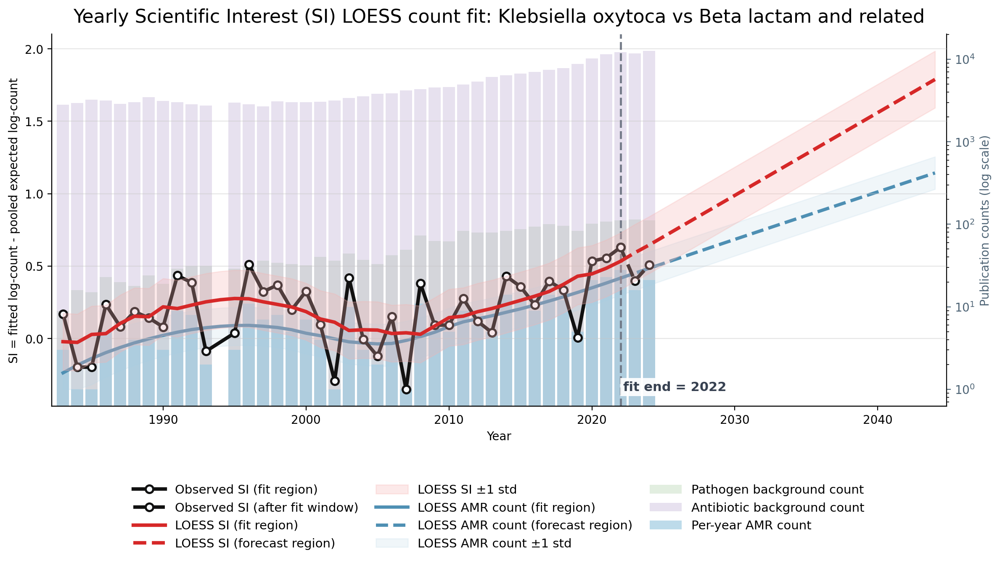

Example plot for Klebsiella oxytoca vs Beta lactam and related (High level categories)
Observed vs predicted yearly AMR counts


,year,observed_count,predicted_count,diff,pct_error
0,1983,3,2,1,33.333333
1,1984,1,2,-1,-100.000000
2,1985,1,2,-1,-100.000000
3,1986,5,3,2,40.000000
4,1987,3,3,0,0.000000
5,1988,4,4,0,0.000000
6,1989,4,4,0,0.000000
7,1990,3,5,-2,-66.666667
8,1991,9,5,4,44.444444
9,1992,8,5,3,37.500000


LOESS fraction: 0.6
LOESS degree: 2
Training residual std on log-count scale: 0.1958259705541141
Latest observed year: 2024


In [10]:
MIN_TRAIN_YEARS = 10
MIN_TOTAL_AMR_COUNT = 200

eligible_pairs = (
    si_df.loc[si_df["year"].between(RANK_FIT_START_YEAR, RANK_FIT_END_YEAR)]
    .groupby(["pathogen", "antibiotic"], as_index=False)
    .agg(
        n_train_years=("year", "nunique"),
        total_count=("count", "sum"),
    )
    .query("n_train_years >= @MIN_TRAIN_YEARS and total_count >= @MIN_TOTAL_AMR_COUNT")
    .reset_index(drop=True)
)

if eligible_pairs.empty:
    raise ValueError(
        f"No pathogen-group pairs have at least {MIN_TRAIN_YEARS} training years "
        f"and total AMR count >= {MIN_TOTAL_AMR_COUNT}."
    )

example_row = eligible_pairs.sample(1, random_state=None).iloc[0]
example_pathogen = example_row["pathogen"]
example_group = example_row["antibiotic"]

print(
    f"Random eligible pair: {example_pathogen} vs {example_group} "
    f"(n_train_years={example_row['n_train_years']}, total_count={example_row['total_count']})"
)


result = plot_yearly_si_pair(
    si_df=si_df,
    pathogen=example_pathogen,
    antibiotic=example_group,
    fit_start_year=RANK_FIT_START_YEAR,
    fit_end_year=RANK_FIT_END_YEAR,
    num_additional_years=RANK_NUM_FUTURE_YEARS,
    loess_frac=0.6,
    loess_degree=2,
    tail_damping_years=None,
)

print(f"Example plot for {example_pathogen} vs {example_group} ({ANTIBIOTIC_GROUP_COLUMN})")
print("Observed vs predicted yearly AMR counts")
display(result["comparison_df"])
print("LOESS fraction:", result["loess_fit"]["frac"])
print("LOESS degree:", result["loess_fit"]["degree"])
print("Training residual std on log-count scale:", result["loess_fit"]["residual_std"])
print("Latest observed year:", result["latest_available_year"])


## Pareto-front examples at the group level


,pareto_shell,pathogen,antibiotic,mean_SI,mean_count,total_count,n_intervals,n_years,latest_year
0,1,Enterococcus faecium,Glycopeptides,0.736252,58.459459,2163,37,37,2024
1,1,Pseudomonas aeruginosa,Beta lactam and related,0.624247,109.980000,5499,50,50,2024
2,1,Escherichia coli,Beta lactam and related,0.519492,211.720000,10586,50,50,2024
3,2,Enterobacter hormaechei,Nitrofuran derivatives,0.639848,1.000000,1,1,1,1989
4,2,Mycobacterium tuberculosis,Rifamycins,0.561708,47.586957,2189,46,46,2025
5,2,Helicobacter pylori,MLS,0.514027,55.656250,1781,32,32,2024
6,2,Klebsiella pneumoniae,Beta lactam and related,0.498569,118.000000,5782,49,49,2024
7,3,Bordetella bronchiseptica,Nitrofuran derivatives,0.623749,1.000000,1,1,1,1975
8,3,Haemophilus influenzae,Beta lactam and related,0.553328,31.380000,1569,50,50,2024
9,3,Helicobacter pylori,Imidazoles,0.515179,35.861111,1291,36,36,2024


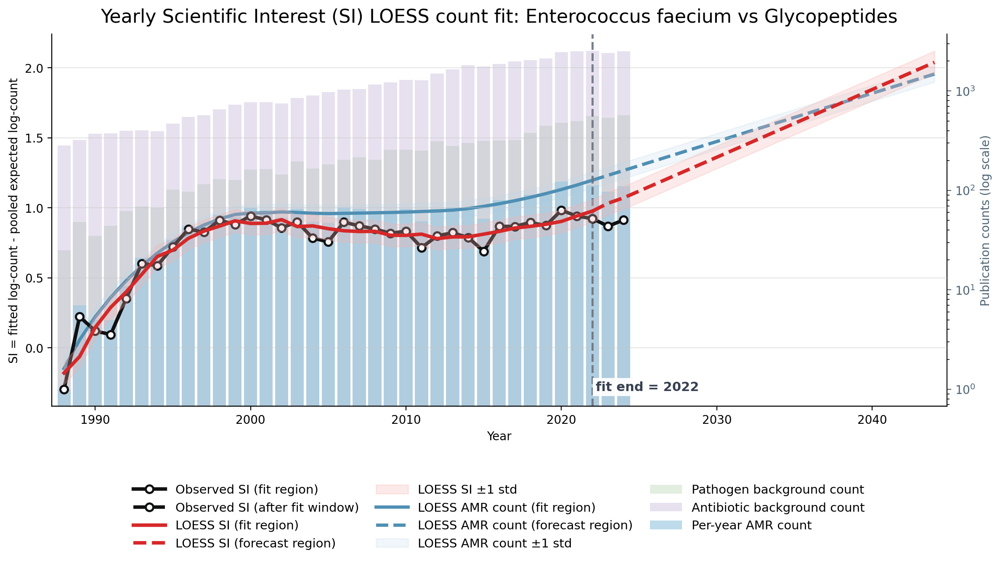

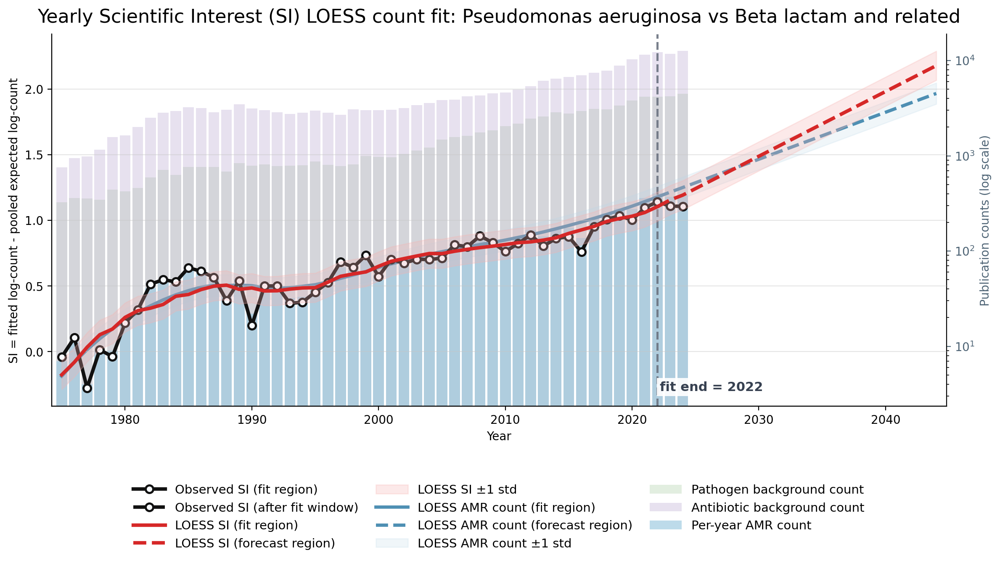

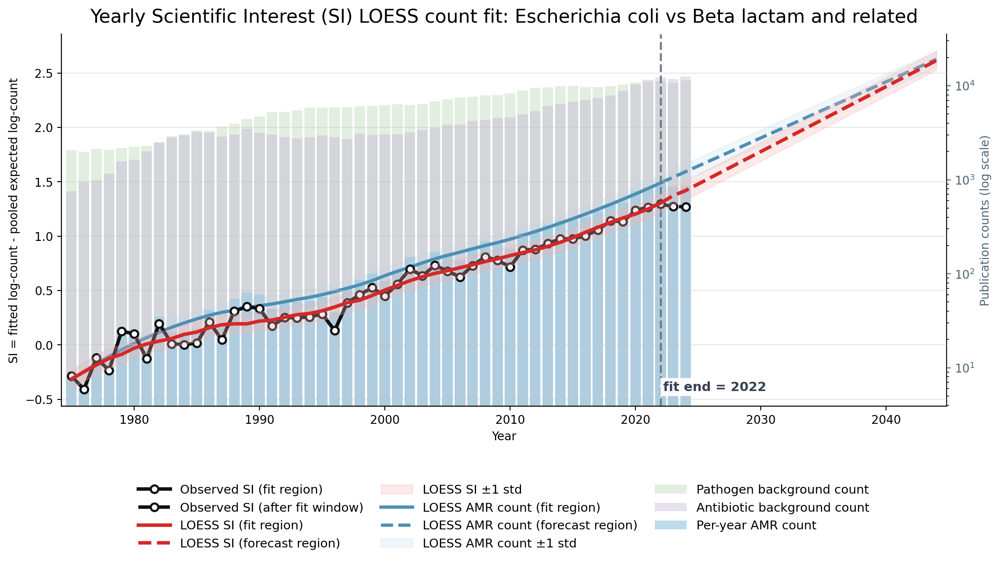

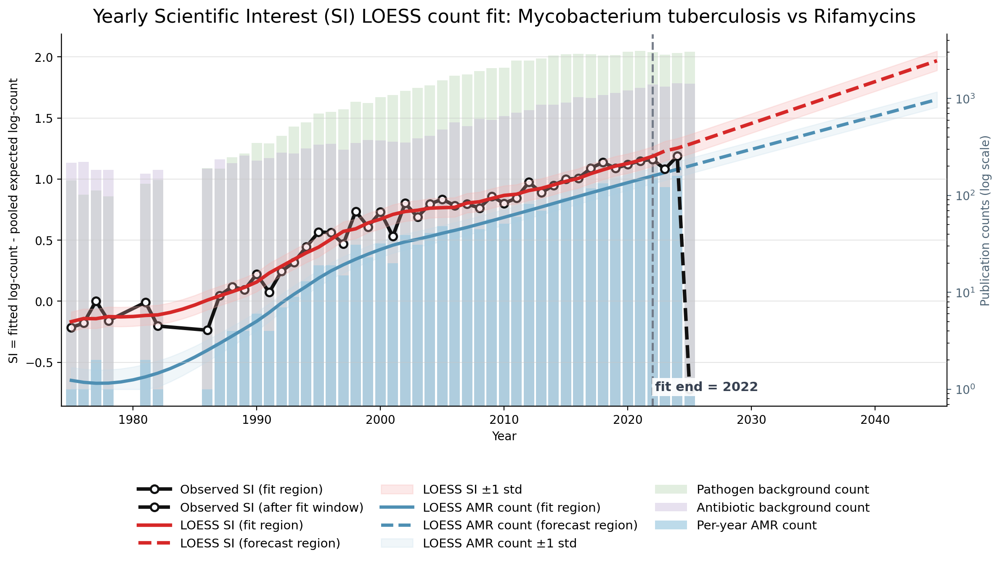

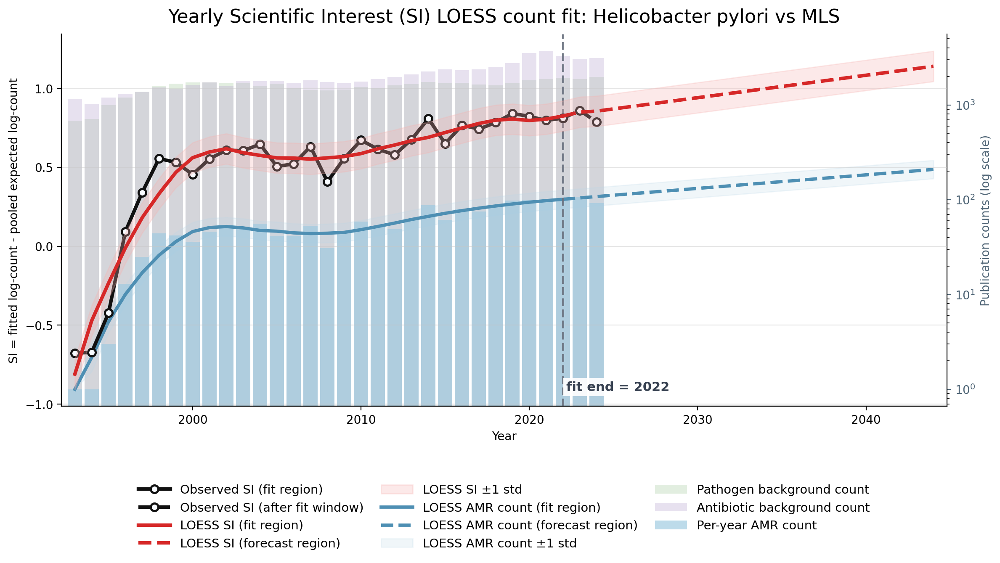

...

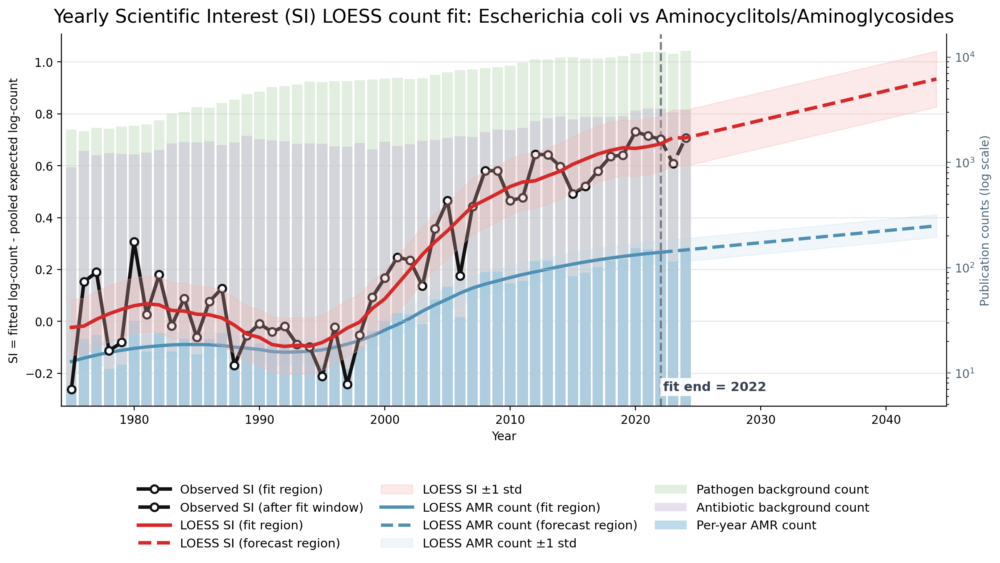

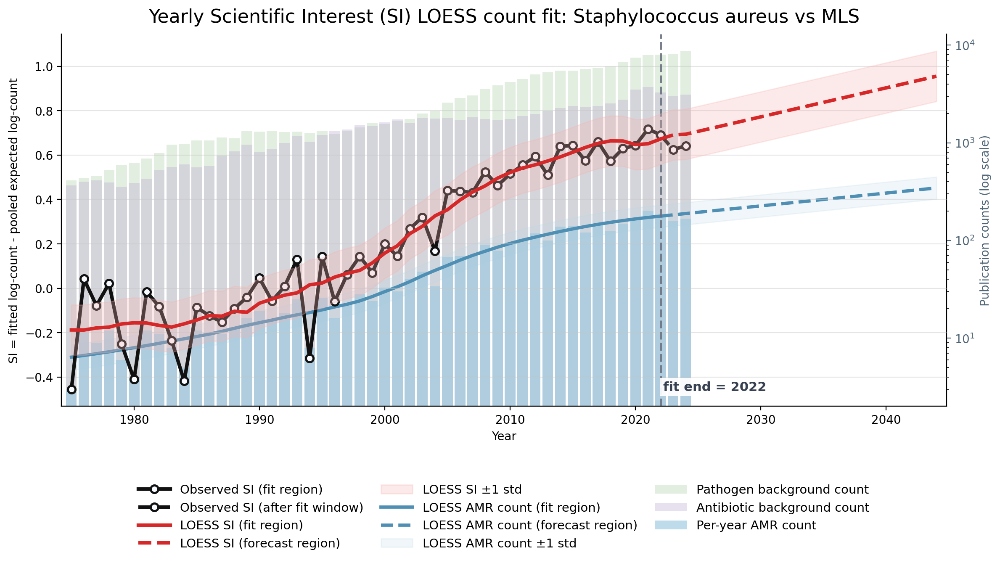

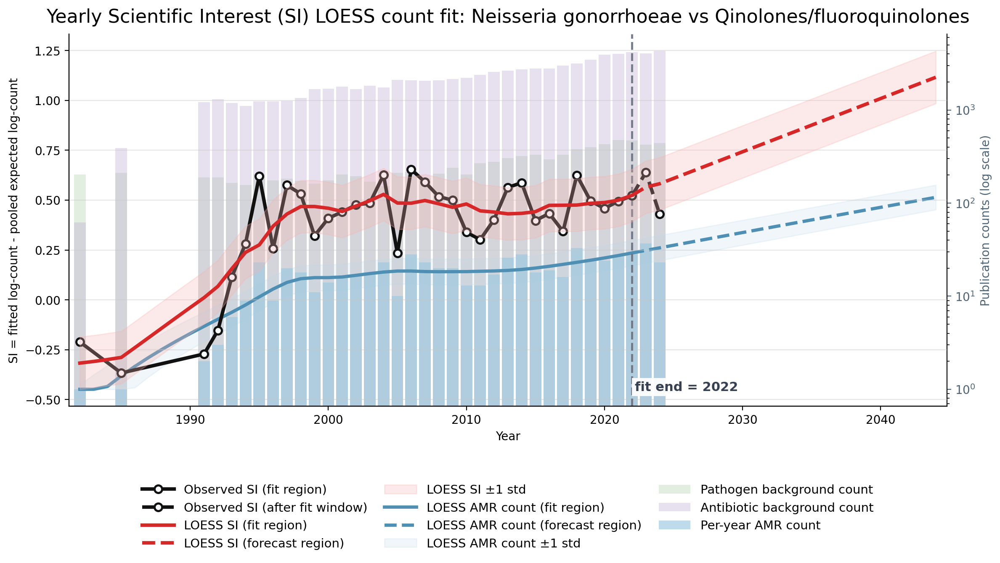

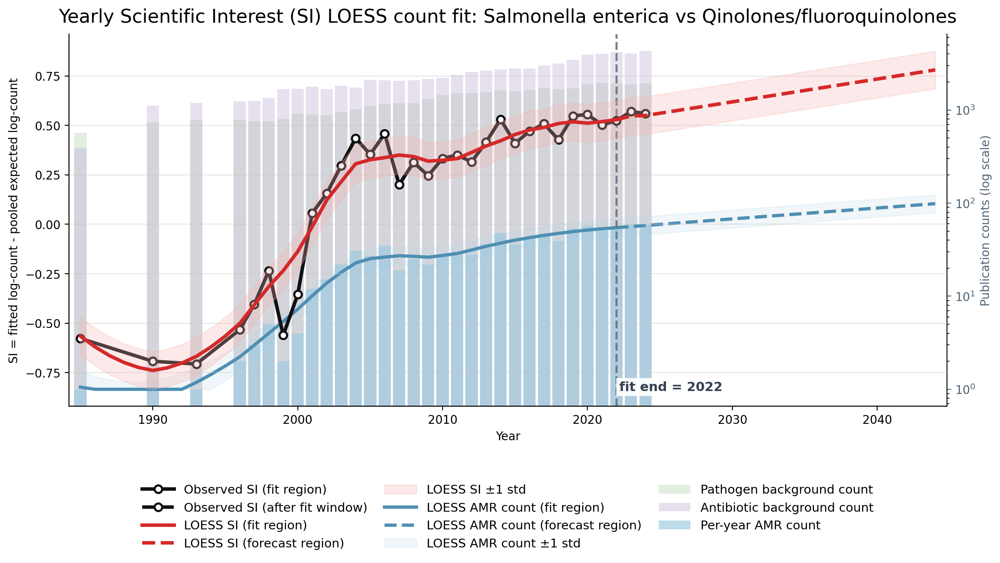

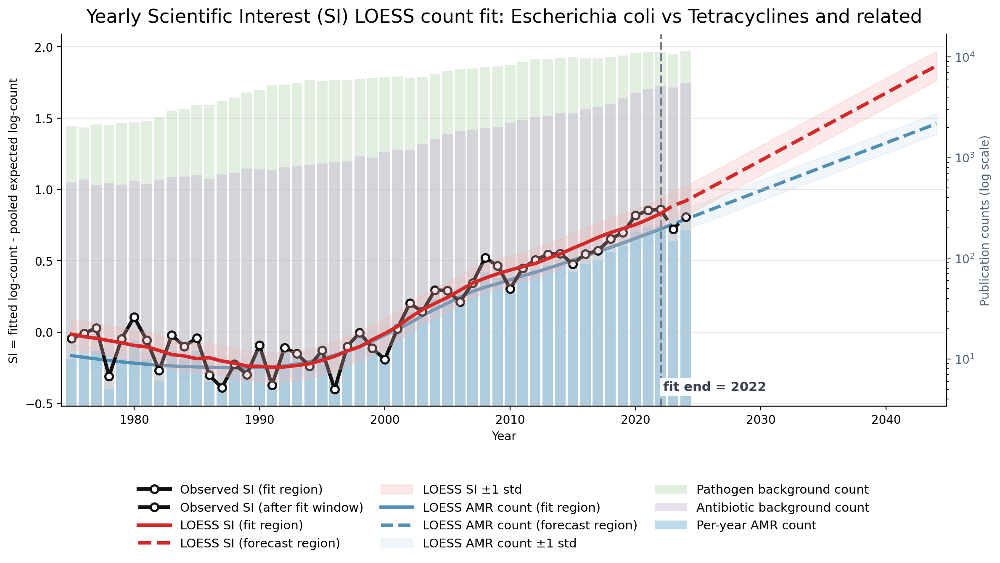

In [11]:
n_pareto_shells = 6
pareto_df = display_si_amr_pareto_front(si_df, n_pareto_shells=n_pareto_shells)
pareto_plot_results = plot_yearly_si_prediction_for_pareto_pairs(
    si_df,
    pareto_df,
    fit_start_year=RANK_FIT_START_YEAR,
    fit_end_year=RANK_FIT_END_YEAR,
    num_additional_years=RANK_NUM_FUTURE_YEARS,
    loess_frac=0.6,
    loess_degree=2,
    tail_damping_years=None,
    n_pareto_shells=n_pareto_shells,
    save_dir=str(PARETO_PNG_DIR),
)


## Rank future SI shifts for pathogen-group pairs


In [12]:
%%time

rank_df = rank_yearly_pairs_by_future_si_shift(
    si_df,
    fit_start_year=RANK_FIT_START_YEAR,
    fit_end_year=RANK_FIT_END_YEAR,
    num_future_years=RANK_NUM_FUTURE_YEARS,
    save_path=str(RANK_OUTPUT_PATH),
    verbose=True,
)


[1/2827] ranking Abiotrophia defectiva vs Beta lactam and related (2826 remaining)
[1/2827] skipping Abiotrophia defectiva vs Beta lactam and related: Need at least 3 observed years between 1970 and 2022; found 2.
[2/2827] ranking Abiotrophia defectiva vs MLS (2825 remaining)
[2/2827] skipping Abiotrophia defectiva vs MLS: Need at least 3 observed years between 1970 and 2022; found 2.
[3/2827] ranking Abiotrophia defectiva vs Other (2824 remaining)
[3/2827] skipping Abiotrophia defectiva vs Other: Need at least 3 observed years between 1970 and 2022; found 1.
[4/2827] ranking Abiotrophia defectiva vs Qinolones/fluoroquinolones (2823 remaining)
[4/2827] skipping Abiotrophia defectiva vs Qinolones/fluoroquinolones: Need at least 3 observed years between 1970 and 2022; found 2.
[5/2827] ranking Abiotrophia defectiva vs Rifamycins (2822 remaining)
[5/2827] skipping Abiotrophia defectiva vs Rifamycins: Need at least 3 observed years between 1970 and 2022; found 1.
[6/2827] ranking Abiotroph

In [13]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

rank_df = pd.read_parquet(RANK_OUTPUT_PATH)

interesting_df = select_interesting_yearly_rank_cases(
    rank_df,
    min_current_predicted_count=10,
    min_si_change=0.1,
    min_post_fit_observed_years=1,
    max_post_fit_si_abs_pct_error_mean=40,
    fallback_top_n=0,
)

minimal_df = interesting_df[
    [
        "pathogen",
        "antibiotic",
        "interest_score",
        "si_change",
        "current_predicted_count",
        "future_predicted_count",
        "post_fit_si_abs_pct_error_mean",
    ]
].copy()

minimal_df


,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,post_fit_si_abs_pct_error_mean
0,Klebsiella pneumoniae,Beta lactam and related,0.927003,0.344938,559.072870,1274.187258,6.924308
1,Escherichia coli,Beta lactam and related,0.739955,0.273071,926.301873,1753.483601,8.683171
2,Klebsiella pneumoniae,Other,0.656156,0.363614,188.172215,442.773624,24.253375
3,Pseudomonas aeruginosa,Beta lactam and related,0.551712,0.217616,370.136461,627.097533,4.919189
4,Klebsiella pneumoniae,Sulfonamides/Trimethoprim derivatives and their combinations,0.534155,0.350499,53.921055,126.954070,27.469536
5,Klebsiella pneumoniae,Tetracyclines and related,0.454831,0.255830,51.441893,96.928353,7.966159
6,Pseudomonas aeruginosa,Other,0.420973,0.241697,49.179428,87.592718,7.842438
7,Escherichia coli,Tetracyclines and related,0.412118,0.212546,196.133757,325.717659,16.942640
8,Pseudomonas aeruginosa,Qinolones/fluoroquinolones,0.406329,0.234041,78.755651,139.154850,15.151897
9,Enterobacter cloacae,Beta lactam and related,0.404586,0.231635,58.285965,98.950326,8.418342


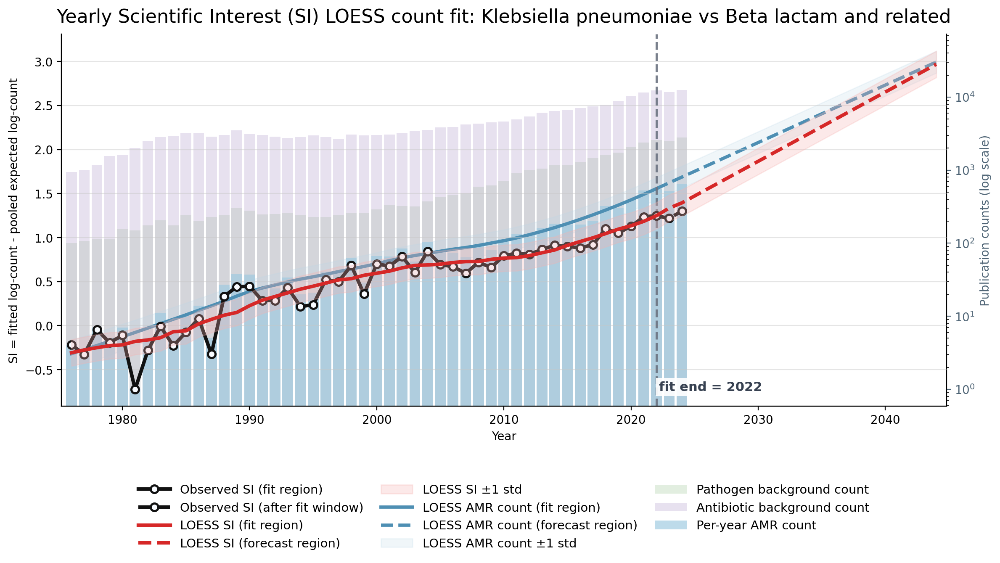

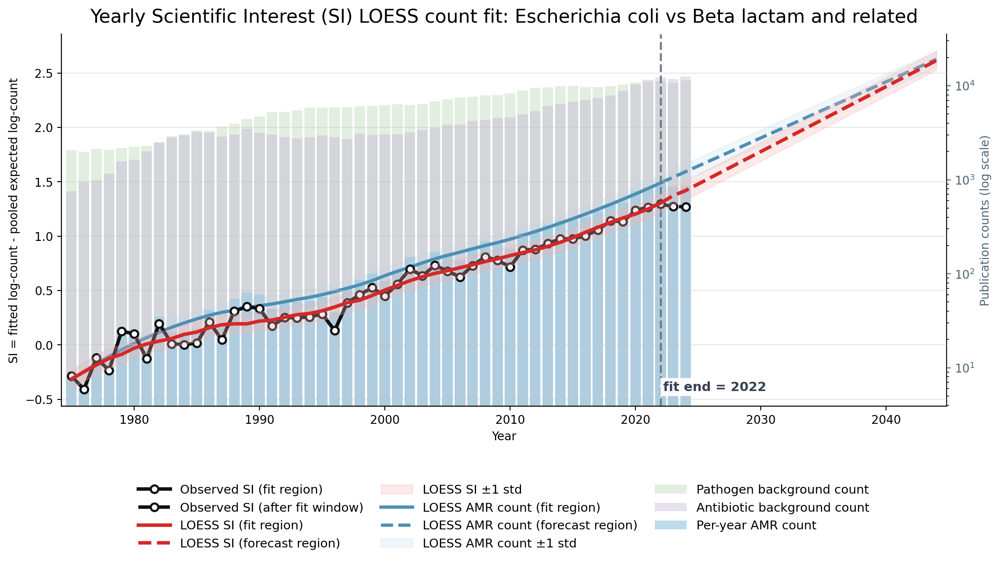

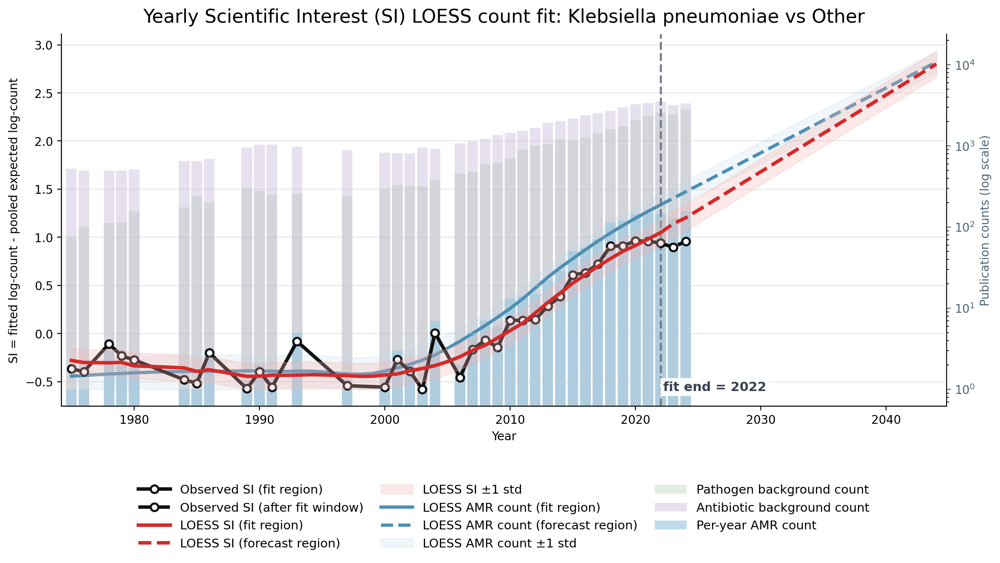

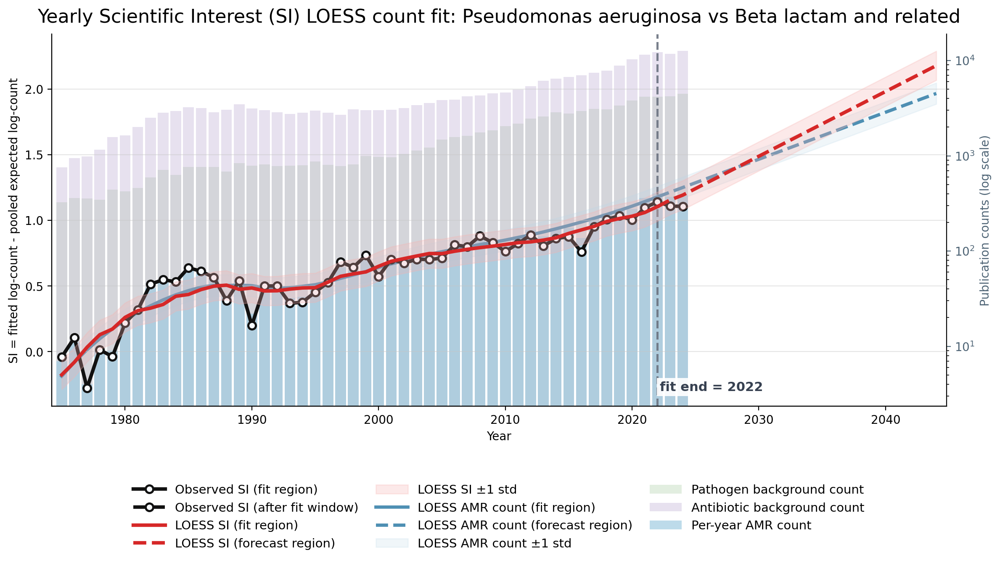

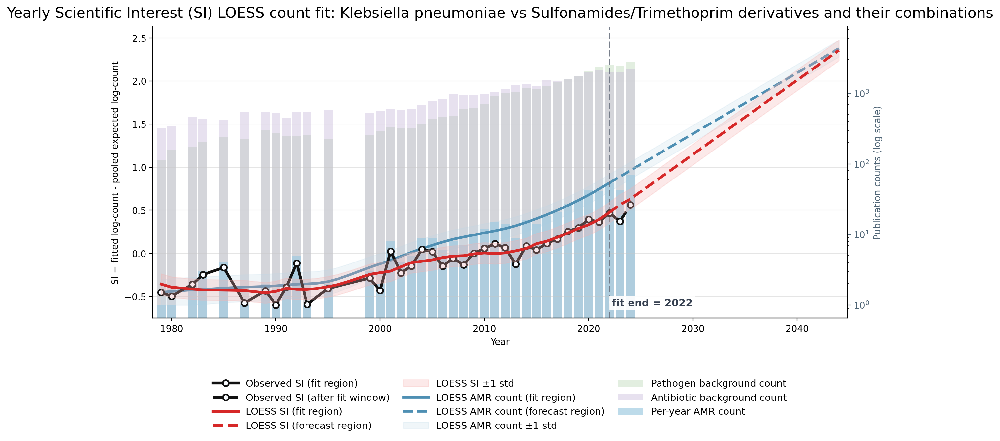

...

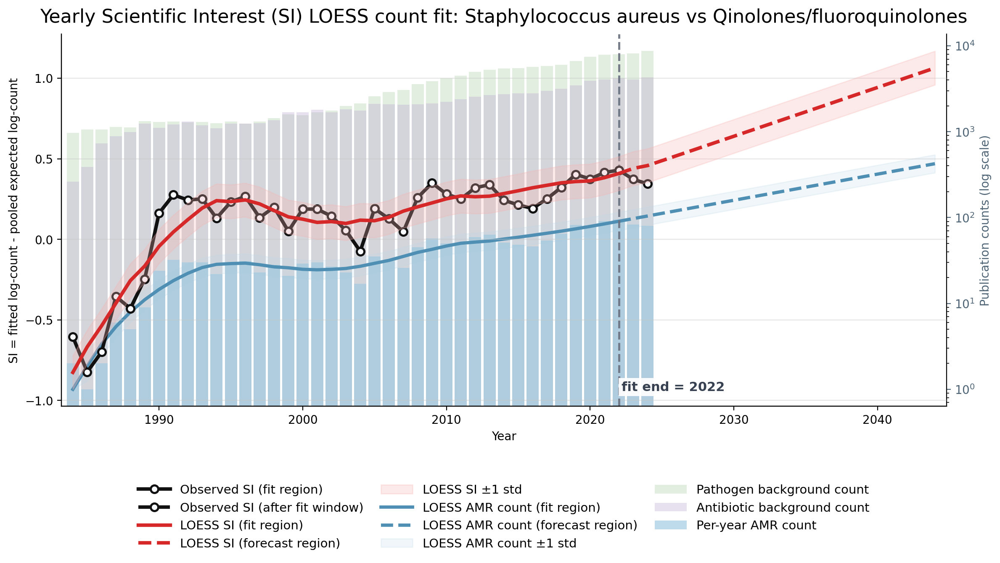

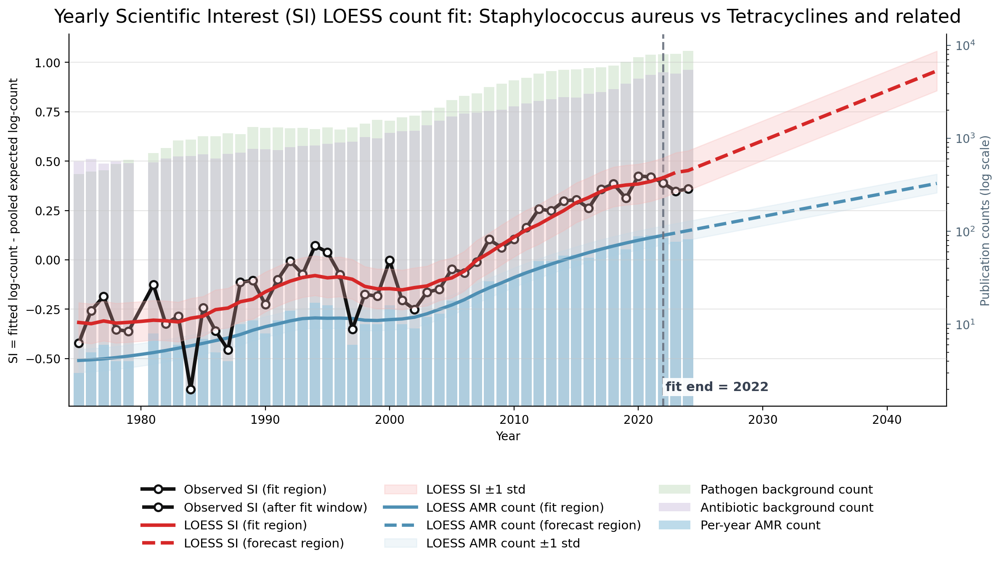

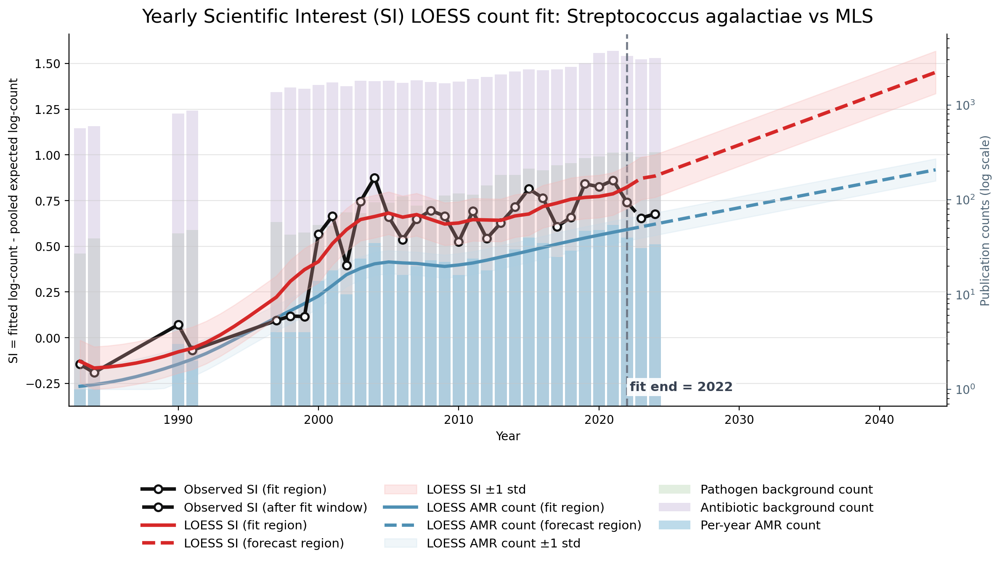

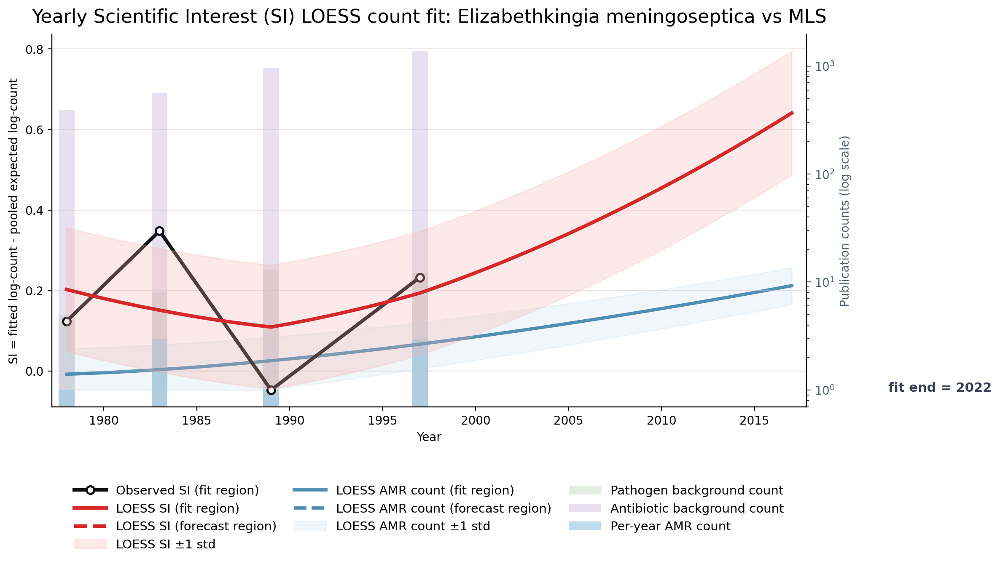

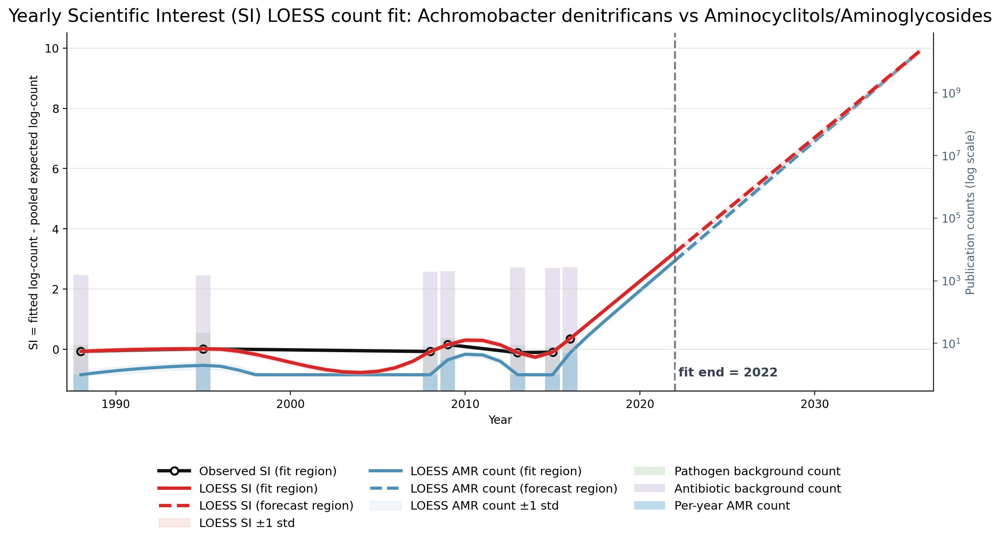

Saved 24 interesting-case PNGs to interesting_yearly_si_pngs_high_level_categories


In [14]:
INTERESTING_PNG_DIR.mkdir(parents=True, exist_ok=True)

for pathogen, antibiotic_group in minimal_df[["pathogen", "antibiotic"]].values:
    result = plot_yearly_si_pair(
        si_df=si_df,
        pathogen=pathogen,
        antibiotic=antibiotic_group,
        fit_start_year=RANK_FIT_START_YEAR,
        fit_end_year=RANK_FIT_END_YEAR,
        num_additional_years=RANK_NUM_FUTURE_YEARS,
        loess_frac=0.6,
        loess_degree=2,
        tail_damping_years=None,
    )

    pathogen_slug = str(pathogen).replace("/", "_").replace(" ", "_")
    group_slug = str(antibiotic_group).replace("/", "_").replace(" ", "_")
    out_path = INTERESTING_PNG_DIR / f"{pathogen_slug}__{group_slug}.png"
    result["figure"].savefig(out_path, dpi=200, bbox_inches="tight")

print(f"Saved {len(minimal_df):,} interesting-case PNGs to {INTERESTING_PNG_DIR}")
